# **1. Reading the most important libraries and Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier


In [2]:
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv('/kaggle/input/obesity-levels/ObesityDataSet_raw_and_data_sinthetic.csv')
df

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.000000,Female,1.620000,64.000000,no,no,2.0,3.0,no,no,2.000000,yes,0.000000,1.000000,Sometimes,Public_Transportation,Normal_Weight
1,21.000000,Female,1.520000,56.000000,Sometimes,no,3.0,3.0,yes,yes,3.000000,yes,3.000000,0.000000,Sometimes,Public_Transportation,Normal_Weight
2,23.000000,Male,1.800000,77.000000,Frequently,no,2.0,3.0,no,no,2.000000,yes,2.000000,1.000000,Sometimes,Public_Transportation,Normal_Weight
3,27.000000,Male,1.800000,87.000000,Frequently,no,3.0,3.0,no,no,2.000000,no,2.000000,0.000000,Sometimes,Walking,Overweight_Level_I
4,22.000000,Male,1.780000,89.800000,Sometimes,no,2.0,1.0,no,no,2.000000,no,0.000000,0.000000,Sometimes,Public_Transportation,Overweight_Level_II
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,20.976842,Female,1.710730,131.408528,Sometimes,yes,3.0,3.0,no,no,1.728139,yes,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,21.982942,Female,1.748584,133.742943,Sometimes,yes,3.0,3.0,no,no,2.005130,yes,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,22.524036,Female,1.752206,133.689352,Sometimes,yes,3.0,3.0,no,no,2.054193,yes,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,24.361936,Female,1.739450,133.346641,Sometimes,yes,3.0,3.0,no,no,2.852339,yes,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III


> # 1.1 - Checking for NAN and duplicate lines in the dataset

In [4]:
df.isna().sum()

Age                               0
Gender                            0
Height                            0
Weight                            0
CALC                              0
FAVC                              0
FCVC                              0
NCP                               0
SCC                               0
SMOKE                             0
CH2O                              0
family_history_with_overweight    0
FAF                               0
TUE                               0
CAEC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

-> There is not NAN in this dataser

In [5]:
duplicates = df.duplicated()
print(duplicates.sum())

24


-> but, there are duplicates lines, so  I will drop duplicates lines from dataset

In [6]:
df.drop_duplicates(inplace=True)

In [7]:
duplicates = df.duplicated()
print(duplicates.sum())

0


-> Now, there aren't duplicates lines 

> #  1.2 - Dropping Outliers

In [8]:
def remove_outliers(df):
    for col in df.select_dtypes(include='number').columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers=(df[col] < lower_bound ) | (df[col] > upper_bound)
        df=df[~outliers]
    return df
df = remove_outliers(df)

In [9]:
df

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.000000,Female,1.620000,64.000000,no,no,2.0,3.0,no,no,2.000000,yes,0.000000,1.000000,Sometimes,Public_Transportation,Normal_Weight
1,21.000000,Female,1.520000,56.000000,Sometimes,no,3.0,3.0,yes,yes,3.000000,yes,3.000000,0.000000,Sometimes,Public_Transportation,Normal_Weight
2,23.000000,Male,1.800000,77.000000,Frequently,no,2.0,3.0,no,no,2.000000,yes,2.000000,1.000000,Sometimes,Public_Transportation,Normal_Weight
3,27.000000,Male,1.800000,87.000000,Frequently,no,3.0,3.0,no,no,2.000000,no,2.000000,0.000000,Sometimes,Walking,Overweight_Level_I
5,29.000000,Male,1.620000,53.000000,Sometimes,yes,2.0,3.0,no,no,2.000000,no,0.000000,0.000000,Sometimes,Automobile,Normal_Weight
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,20.976842,Female,1.710730,131.408528,Sometimes,yes,3.0,3.0,no,no,1.728139,yes,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,21.982942,Female,1.748584,133.742943,Sometimes,yes,3.0,3.0,no,no,2.005130,yes,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,22.524036,Female,1.752206,133.689352,Sometimes,yes,3.0,3.0,no,no,2.054193,yes,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,24.361936,Female,1.739450,133.346641,Sometimes,yes,3.0,3.0,no,no,2.852339,yes,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III


-> With that, the dataset has 1376 rows, before, the dataset had 2111 rows

#  **2.0-Modeling the Machine Learning**

In [10]:
X = df.iloc[:,0:16].values
y= df.iloc[:,16].values

-> Here, I'm defining the variables X and y, X are the columns without the “NObeyesdad” column, which is our target, and y are the “NObeyesdad” columns, which is the target

In [11]:
labelencoder1 = LabelEncoder()
X[:,1] = labelencoder1.fit_transform(X[:,1])

labelencoder2 = LabelEncoder()
X[:,4] = labelencoder2.fit_transform(X[:,4])

labelencoder3 = LabelEncoder()
X[:,5] = labelencoder3.fit_transform(X[:,5])

labelencoder4 = LabelEncoder()
X[:,8] = labelencoder4.fit_transform(X[:,8])

labelencoder5 = LabelEncoder()
X[:,9] = labelencoder5.fit_transform(X[:,9])

labelencoder6 = LabelEncoder()
X[:,11] = labelencoder6.fit_transform(X[:,11])

labelencoder7 = LabelEncoder()
X[:,14] = labelencoder7.fit_transform(X[:,14])

labelencoder8 = LabelEncoder()
X[:,15] = labelencoder7.fit_transform(X[:,15])

In [12]:
X[:,4]


array([2, 1, 0, ..., 1, 1, 1], dtype=object)

-> Machine leraning doesn't work with string columns, so I'm defining with the label encoder that string columns are read as string columns, which will replace the names with numbers.

In [13]:
scaler = StandardScaler()
X_scaler = scaler.fit_transform(X)
X_scaler

array([[-0.52275596, -1.03250475, -1.07927772, ...,  0.51674887,
         0.30536695,  0.39385877],
       [-0.52275596, -1.03250475, -2.2249336 , ..., -1.19790036,
         0.30536695,  0.39385877],
       [-0.04240538,  0.96851854,  0.98290285, ...,  0.51674887,
         0.30536695,  0.39385877],
       ...,
       [-0.15672017, -1.03250475,  0.43534808, ..., -0.08974314,
         0.30536695,  0.39385877],
       [ 0.284698  , -1.03250475,  0.28920822, ..., -0.1930559 ,
         0.30536695,  0.39385877],
       [ 0.1172413 , -1.03250475,  0.28217389, ...,  0.02659409,
         0.30536695,  0.39385877]])

-> I'm making the variable X standardized, so that it's not too far apart, the values of X

> # 2.1 - Training and Testing division process

In [14]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X_scaler,
                                                        y,
                                                        test_size= 0.2,
                                                        random_state= 0)

>  **2.1.1 - Naive bayes**

In [15]:
naive_bayes = GaussianNB()
naive_bayes.fit(X_treino, y_treino)


GaussianNB()

In [16]:
previsoes = naive_bayes.predict(X_teste)



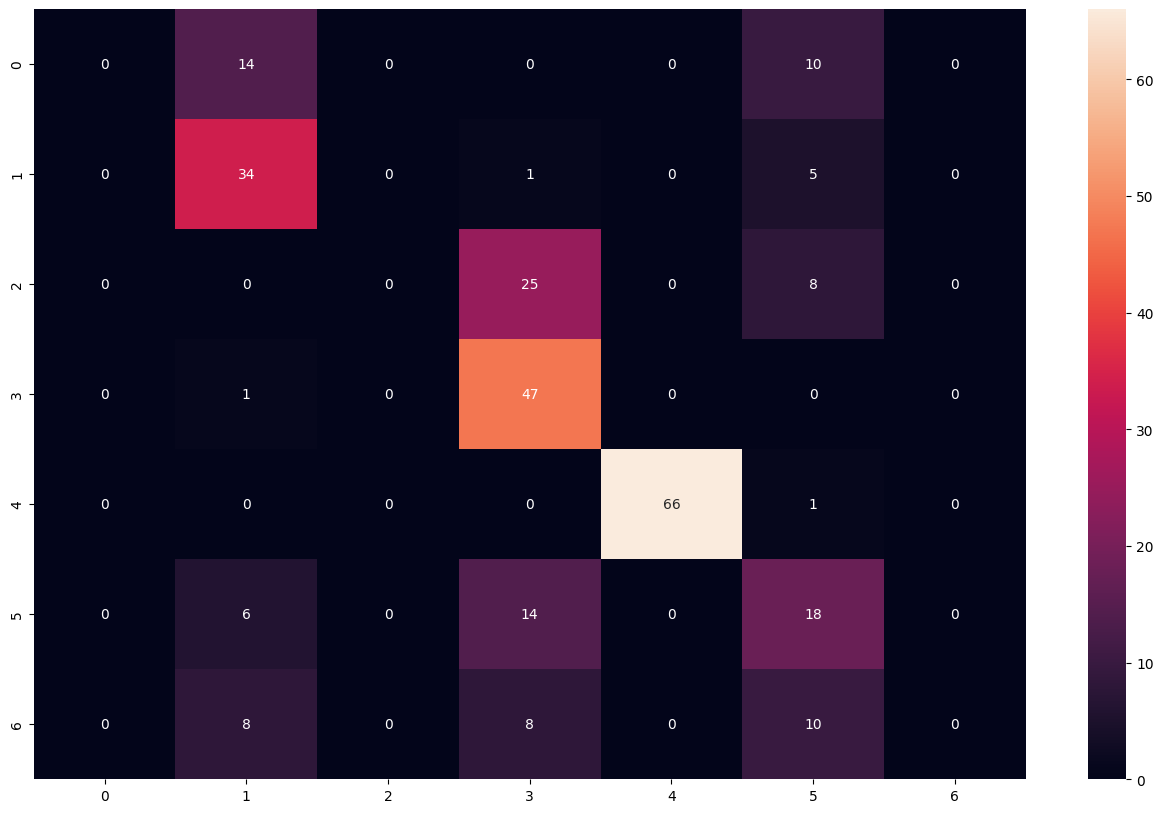

In [17]:
matrix_confussion = confusion_matrix(y_teste, previsoes) 
plt.figure(figsize=(16, 10))
sns.heatmap(matrix_confussion, annot=True)
plt.show()

In [18]:
taxa_acerto = accuracy_score(y_teste, previsoes)
print(f'The accuracy score is {taxa_acerto * 100:.1f}%')

The accuracy score is 59.8%


>  **2.1.2 - Decision Tree**


In [19]:
arvore = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore.fit(X_treino, y_treino)


DecisionTreeClassifier(criterion='entropy', random_state=0)

In [20]:
previsoes2 = arvore.predict(X_teste)


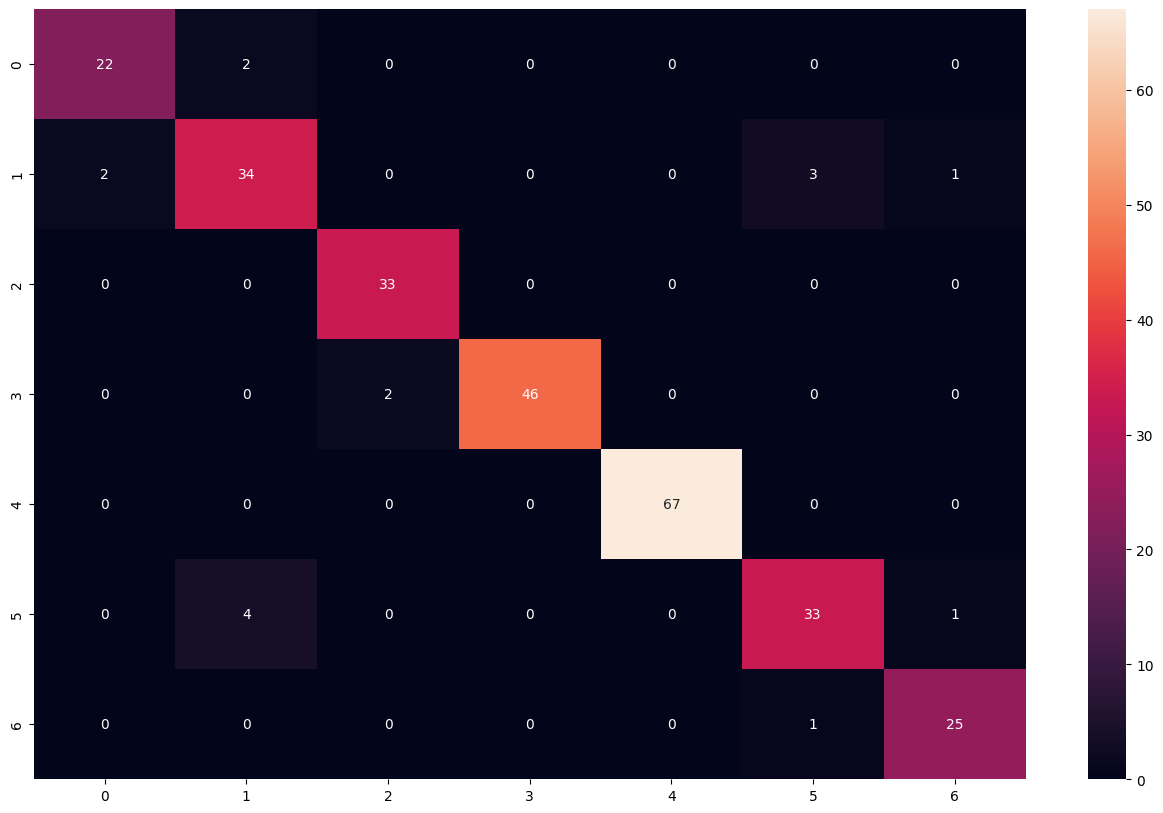

In [21]:
matrix_confussion2 = confusion_matrix(y_teste, previsoes2)
plt.figure(figsize=(16, 10))
sns.heatmap(matrix_confussion2, annot=True)
plt.show()

In [22]:
taxa_acerto2 = accuracy_score(y_teste, previsoes2)
print(f'The accuracy score is  {taxa_acerto2 * 100:.1f}%')

The accuracy score is  94.2%


>  **2.1.3 - Random forest**

In [23]:
random_forest = RandomForestClassifier(criterion='gini', random_state=0)
random_forest.fit(X_treino, y_treino)


RandomForestClassifier(random_state=0)

In [24]:
previsoes3 = random_forest.predict(X_teste)


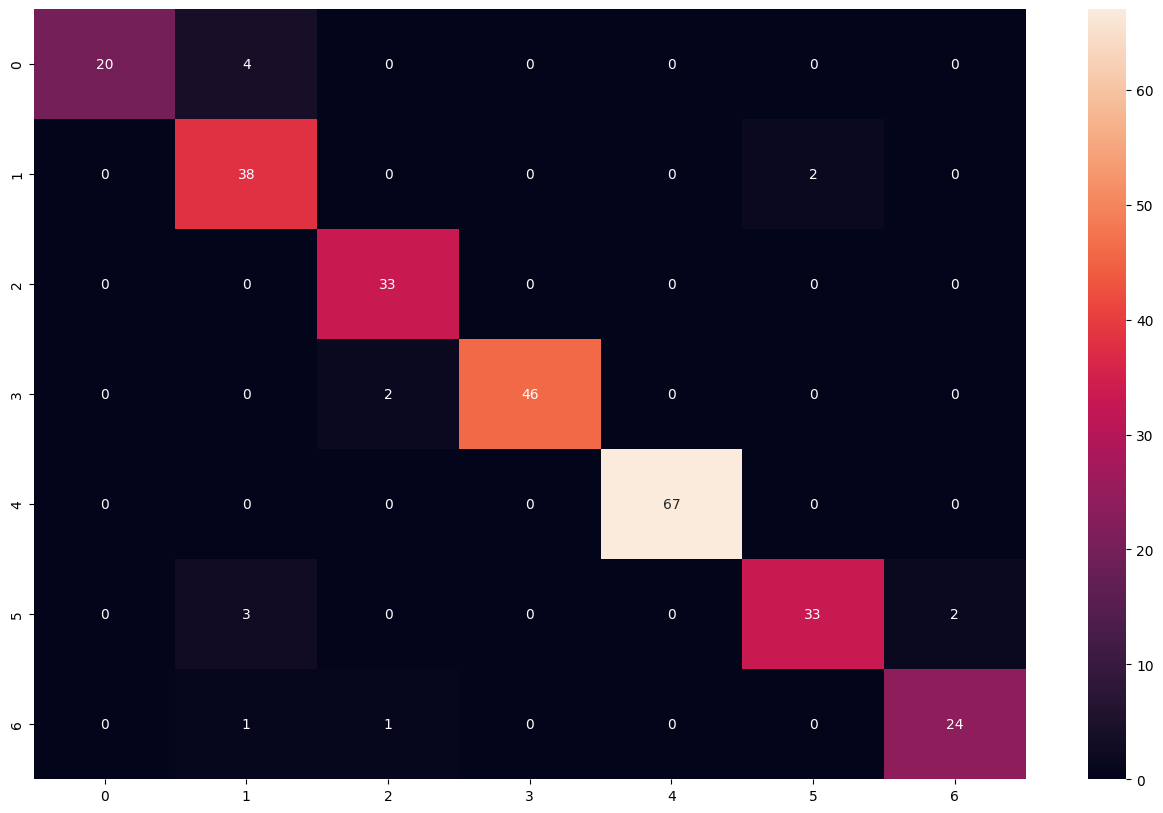

In [25]:
matrix_confussion3 = confusion_matrix(y_teste, previsoes3)
plt.figure(figsize=(16, 10))
sns.heatmap(matrix_confussion3, annot=True)
plt.show()

In [26]:
taxa_acerto3 = accuracy_score(y_teste, previsoes3)
print(f'The accuracy score is {taxa_acerto3 * 100:.1f}%')

The accuracy score is 94.6%


>  **2.1.4 - KNN**

In [27]:
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_treino, y_treino)

KNeighborsClassifier(n_neighbors=3)

In [28]:
previsoes4 = knn.predict(X_teste)

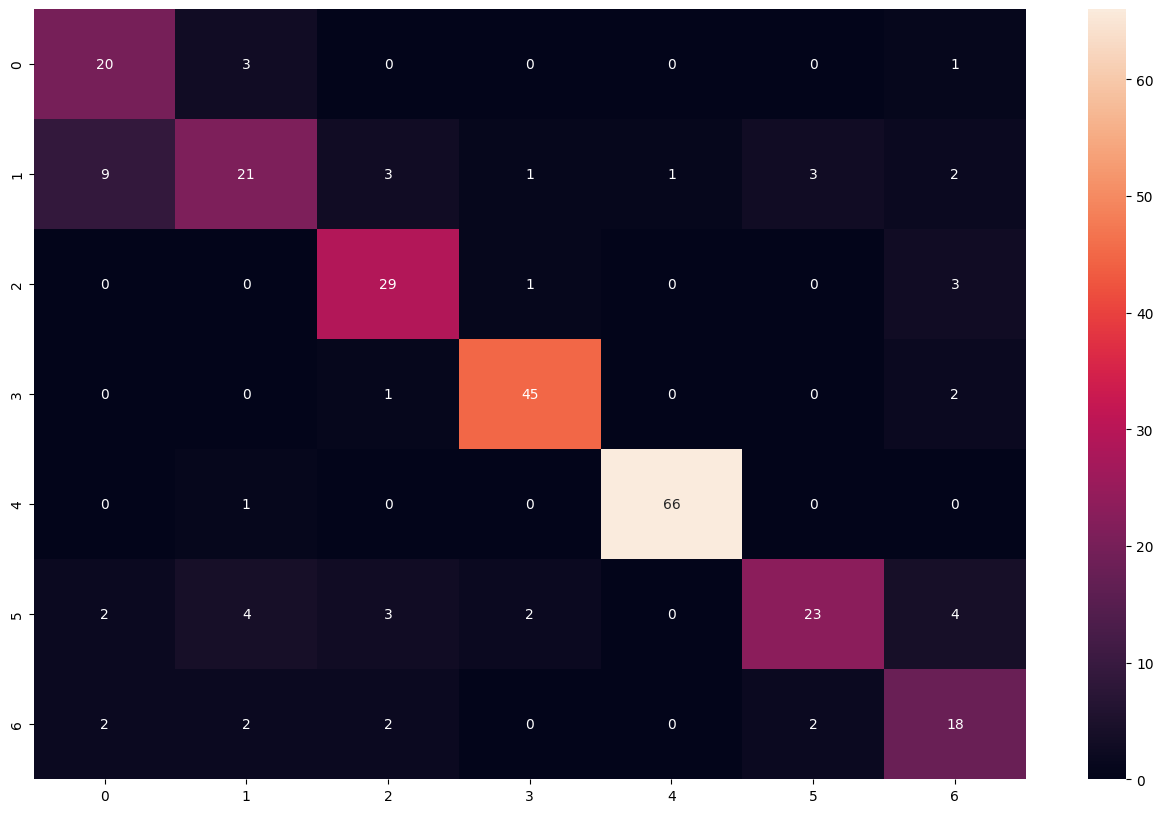

In [29]:
matrix_confussion4 = confusion_matrix(y_teste, previsoes4)
plt.figure(figsize=(16, 10))
sns.heatmap(matrix_confussion4, annot=True)
plt.show()


In [30]:
taxa_acerto4 = accuracy_score(y_teste, previsoes4)
print(f'The accuracy score is  {taxa_acerto4 * 100:.1f}%')

The accuracy score is  80.4%


>  **2.1.5 - Logistic Regression**

In [31]:
logistic_regression = LogisticRegression(random_state = 0, max_iter=2000, C=4.0)
logistic_regression.fit(X_treino, y_treino)



LogisticRegression(C=4.0, max_iter=2000, random_state=0)

In [32]:
previsoes5 = logistic_regression.predict(X_teste)

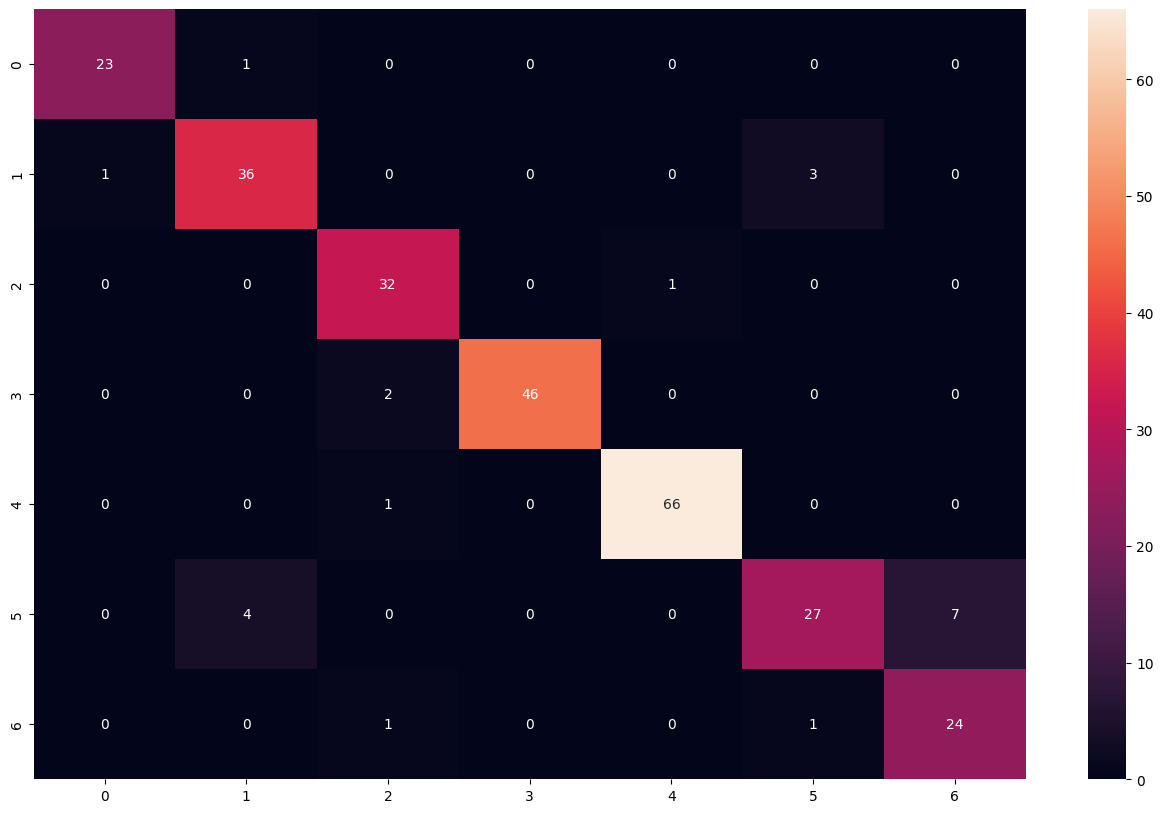

In [33]:
matrix_confussion5 = confusion_matrix(y_teste, previsoes5)
plt.figure(figsize=(16, 10))
sns.heatmap(matrix_confussion5, annot=True)
plt.show()

In [34]:
taxa_acerto5 = accuracy_score(y_teste, previsoes5)
print(f'The accuracy score is  {taxa_acerto5 * 100:.1f}%')

The accuracy score is  92.0%


>  **2.1.6 - SVM**

In [35]:
svm = SVC(kernel = 'linear', random_state=101, C=5.0)
svm.fit(X_treino, y_treino)

SVC(C=5.0, kernel='linear', random_state=101)

In [36]:
previsoes6 = svm.predict(X_teste)

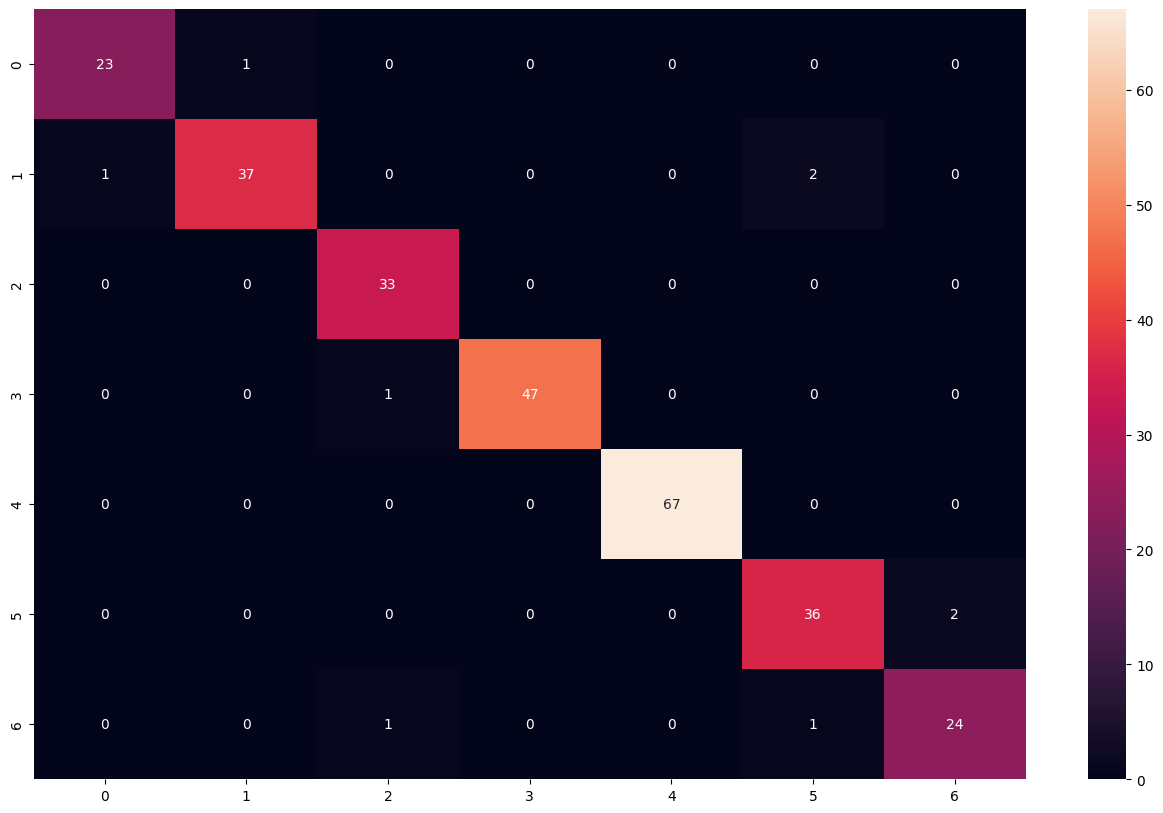

In [37]:
matrix_confussion6 = confusion_matrix(y_teste, previsoes6)
plt.figure(figsize=(16, 10))
sns.heatmap(matrix_confussion6, annot=True)
plt.show()

In [38]:
taxa_acerto6 = accuracy_score(y_teste, previsoes6)
print(f'The accuracy score is  {taxa_acerto6 * 100:.1f}%')

The accuracy score is  96.7%


>  **2.1.7 - Neural network**

In [39]:
neural_network = MLPClassifier(max_iter=3000, tol=0.00000100, hidden_layer_sizes=(10,10),random_state=101, activation='tanh',solver='adam', batch_size=10)
neural_network.fit(X_treino, y_treino)

MLPClassifier(activation='tanh', batch_size=10, hidden_layer_sizes=(10, 10),
              max_iter=3000, random_state=101, tol=1e-06)

In [40]:
previsoes7 = neural_network.predict(X_teste)

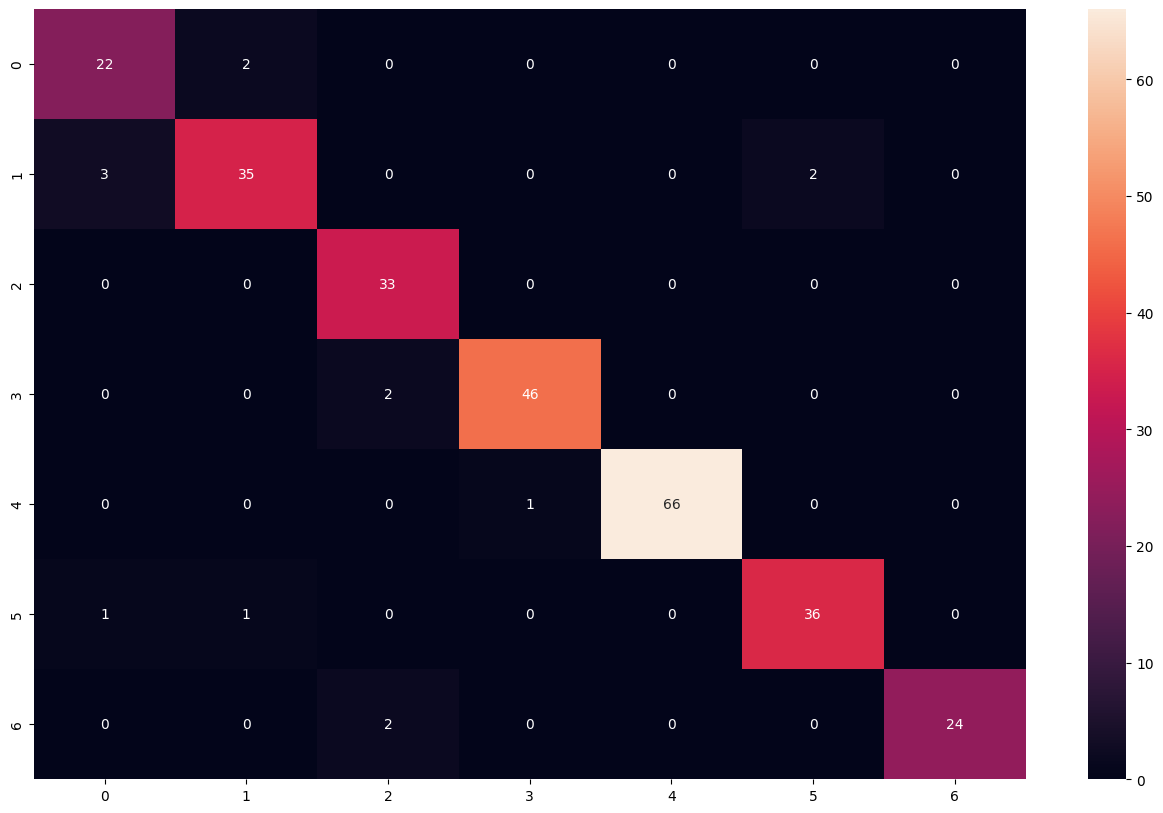

In [41]:
matrix_confussion7 = confusion_matrix(y_teste, previsoes7)
plt.figure(figsize=(16, 10))
sns.heatmap(matrix_confussion7, annot=True)
plt.show()

In [42]:
taxa_acerto7 = accuracy_score(y_teste, previsoes7)
print(f'The accuracy score is  {taxa_acerto7 * 100:.1f}%')

The accuracy score is  94.9%


In [43]:
 previsoes_totais = [f'Naive Bayes: {taxa_acerto * 100:.1f}%', 
                    f'Decision Tree: {taxa_acerto2 * 100:.1f}%',
                    f'Random Forest: {taxa_acerto3 * 100:.1f}%',
                    f'KNN: {taxa_acerto4 * 100:.1f}%',
                    'Rules: 84.0% (using Orange)',
                    f'Logistic Regression: {taxa_acerto5 * 100:.1f}%',
                    f'SVM: {taxa_acerto6 * 100:.1f}%',
                    f'neural {taxa_acerto7 * 100:.1f}%']
    

for previsao in previsoes_totais:
  print(previsao)

Naive Bayes: 59.8%
Decision Tree: 94.2%
Random Forest: 94.6%
KNN: 80.4%
Rules: 84.0% (using Orange)
Logistic Regression: 92.0%
SVM: 96.7%
neural 94.9%


 #  **3.0- Defining better forecast parameters**

In [44]:
parametros = {'criterion': ['gini', 'entropy'],
              'splitter': ['best', 'random'],
              'min_samples_split': [2, 5, 10],
              'min_samples_leaf': [1, 5, 10]}

In [45]:
grid_search = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=parametros)
grid_search.fit(X_treino, y_treino)
melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_
print(melhores_parametros)
print(melhor_resultado)

{'criterion': 'entropy', 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'}
0.9463636363636363


In [46]:
parametros = {'criterion': ['gini', 'entropy'],
              'n_estimators': [10, 40, 100, 150],
              'min_samples_split': [2, 5, 10],
              'min_samples_leaf': [1, 5, 10]}

In [47]:
grid_search = GridSearchCV(estimator=RandomForestClassifier(), param_grid=parametros)
grid_search.fit(X_treino, y_treino)
melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_
print(melhores_parametros)
print(melhor_resultado)

{'criterion': 'gini', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 150}
0.9481818181818182


In [48]:
parametros = {'n_neighbors': [3, 5, 10, 20],
              'p': [1, 2]}

In [49]:
grid_search = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=parametros)
grid_search.fit(X_treino, y_treino)
melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_
print(melhores_parametros)
print(melhor_resultado)

{'n_neighbors': 3, 'p': 1}
0.8536363636363635


In [50]:
parametros = {'tol': [0.0001, 0.00001, 0.000001],
              'C': [1.0, 1.5, 2.0],
              'solver': ['lbfgs', 'sag', 'saga']}

In [51]:
grid_search = GridSearchCV(estimator=LogisticRegression(), param_grid=parametros)
grid_search.fit(X_treino, y_treino)
melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_
print(melhores_parametros)
print(melhor_resultado)

{'C': 2.0, 'solver': 'lbfgs', 'tol': 0.0001}
0.8663636363636364


In [52]:
parametros = {'tol': [0.001, 0.0001, 0.00001],
              'C': [1.0, 1.5, 2.0],
              'kernel': ['rbf', 'linear', 'poly', 'sigmoid']}

In [53]:
grid_search = GridSearchCV(estimator=SVC(), param_grid=parametros)
grid_search.fit(X_treino, y_treino)
melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_
print(melhores_parametros)
print(melhor_resultado)

{'C': 2.0, 'kernel': 'linear', 'tol': 0.001}
0.9472727272727273


In [54]:
parametros = {'activation': ['relu', 'logistic', 'tahn'],
              'solver': ['adam', 'sgd'],
              'batch_size': [10, 56]}

In [55]:
grid_search = GridSearchCV(estimator=MLPClassifier(), param_grid=parametros)
grid_search.fit(X_treino, y_treino)
melhores_parametros = grid_search.best_params_
melhor_resultado = grid_search.best_score_
print(melhores_parametros)
print(melhor_resultado)

{'activation': 'logistic', 'batch_size': 10, 'solver': 'adam'}
0.9481818181818182


In [56]:
from sklearn.model_selection import cross_val_score, KFold
import multiprocessing

# **4.0 - Cross Validation**

In [57]:
resultados_arvore = []
resultados_random_forest = []
resultados_knn = []
resultados_logistica = []
resultados_svm = []
resultados_rede_neural = []

for i in range(30):
  print(i)
  kfold = KFold(n_splits=10, shuffle=True, random_state=i)

  arvore = DecisionTreeClassifier(criterion='entropy', min_samples_leaf=1, min_samples_split=2, splitter='best')
  scores = cross_val_score(arvore, X_treino, y_treino, cv = kfold, n_jobs=-1)
  #print(scores)
  #print(scores.mean())
  resultados_arvore.append(scores.mean())

  random_forest = RandomForestClassifier(criterion = 'gini', min_samples_leaf = 1, min_samples_split=5, n_estimators = 100)
  scores = cross_val_score(random_forest, X_treino, y_treino, cv = kfold, n_jobs=-1)
  resultados_random_forest.append(scores.mean())

  knn = KNeighborsClassifier(n_neighbors = 3, p= 1)
  scores = cross_val_score(knn, X_treino, y_treino, cv = kfold, n_jobs=-1)
  resultados_knn.append(scores.mean())

  logistica = LogisticRegression(C = 2.0, solver = 'lbfgs', tol = 0.00001)
  scores = cross_val_score(logistic_regression, X_treino, y_treino, cv = kfold, n_jobs=-1)
  resultados_logistica.append(scores.mean())

  svm = SVC(kernel = 'linear', C = 2.0, tol=0.001)
  scores = cross_val_score(svm, X_treino, y_treino, cv = kfold, n_jobs=-1)
  resultados_svm.append(scores.mean())

  rede_neural = MLPClassifier(activation = 'logistic', batch_size = 10, solver = 'adam', hidden_layer_sizes=(10,10))
  scores = cross_val_score(neural_network, X_treino, y_treino, cv = kfold, n_jobs=-1)
  resultados_rede_neural.append(scores.mean())


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29


-> here I'm going to use cross validation, so that it repeats this code 30 times, and using the k-fold method, which shows it will divide a part for testing and then the rest for training, then in the other part of the division, another part will be for testing, and the rest for training, this will happen until all the divisions made by kfold are tested and trained, thus showing a more accurate hit rate and close to reality (100% translator)

In [58]:
resultados = pd.DataFrame({'Decison Tree': resultados_arvore, 'Random forest': resultados_random_forest,
                           'KNN': resultados_knn, 'Logistic': resultados_logistica,
                           'SVM': resultados_svm, 'Neural_network': resultados_rede_neural})
resultados

,Decison Tree,Random forest,KNN,Logistic,SVM,Neural_network
0,0.945455,0.955455,0.866364,0.902727,0.952727,0.949091
1,0.943636,0.938182,0.856364,0.904545,0.953636,0.948182
2,0.942727,0.951818,0.859091,0.899091,0.952727,0.950909
3,0.935455,0.944545,0.857273,0.900000,0.952727,0.950909
4,0.957273,0.950909,0.863636,0.906364,0.949091,0.960909
5,0.939091,0.946364,0.862727,0.902727,0.960000,0.958182
6,0.940909,0.950000,0.861818,0.903636,0.950909,0.952727
7,0.950909,0.946364,0.860909,0.902727,0.950000,0.942727
8,0.945455,0.954545,0.860000,0.903636,0.952727,0.953636
9,0.943636,0.949091,0.860000,0.900909,0.957273,0.950000


In [59]:
resultados.describe()

,Decison Tree,Random forest,KNN,Logistic,SVM,Neural_network
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,0.943424,0.948515,0.860545,0.902364,0.953212,0.951606
std,0.004937,0.003718,0.002978,0.002841,0.002666,0.004387
min,0.932727,0.938182,0.855455,0.897273,0.949091,0.942727
25%,0.940227,0.946364,0.858409,0.900909,0.951818,0.948409
50%,0.943636,0.949091,0.860000,0.902727,0.952727,0.951818
75%,0.945455,0.951591,0.862727,0.903636,0.953636,0.954318
max,0.957273,0.955455,0.867273,0.909091,0.960000,0.960909


-> So, The methods with the highest averages are SVM, Neural Network, random forest, Descion Tree, Logistic and knn respectively, and the methods has smallest standard deviation are knn, logistic and SVM

# **5.0 - Normal Distribution**

-> Here, I using ANOVA and Tukey to see which method is part of the normal distribution 

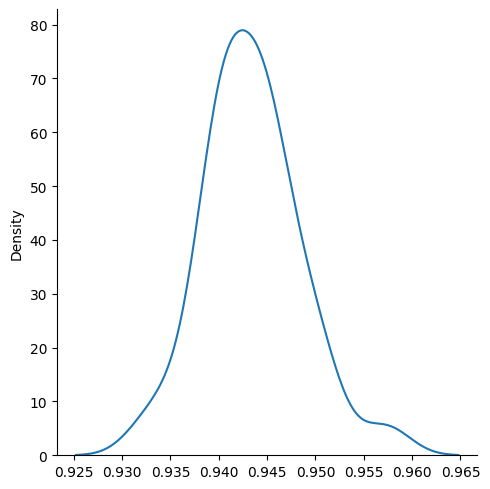

In [60]:
sns.displot(resultados_arvore, kind = 'kde');

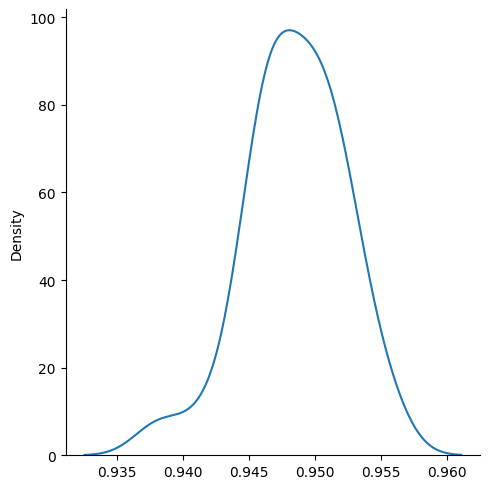

In [61]:
sns.displot(resultados_random_forest, kind = 'kde');

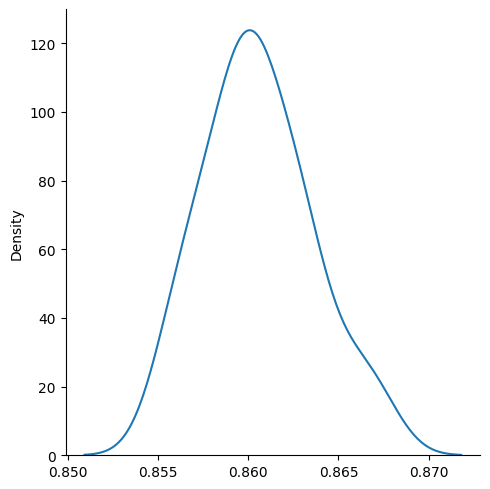

In [62]:
sns.displot(resultados_knn, kind = 'kde');

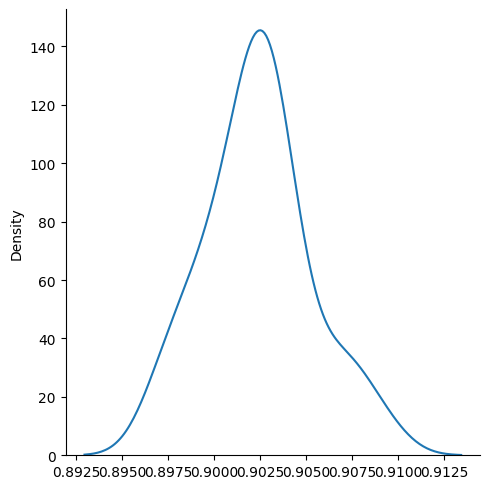

In [63]:
sns.displot(resultados_logistica, kind = 'kde');

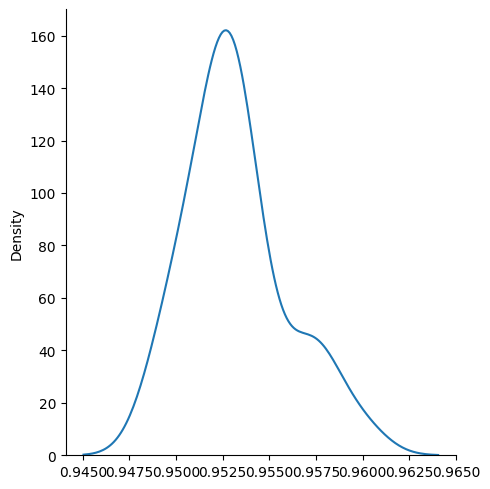

In [64]:
sns.displot(resultados_svm, kind = 'kde');

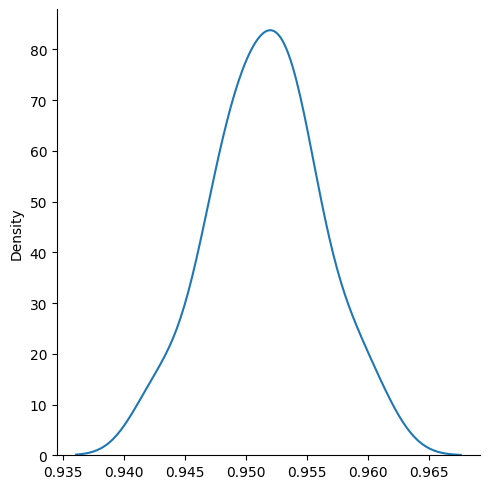

In [65]:
sns.displot(resultados_rede_neural, kind = 'kde');

In [66]:
from scipy.stats import f_oneway

In [67]:
_, p = f_oneway(resultados_arvore, resultados_random_forest, resultados_knn, resultados_logistica, resultados_svm, resultados_rede_neural)
p


3.7608131492282053e-168

In [68]:
alpha = 0.05
if p <= alpha:
  print('Null hypothesis rejected. Data is different')
else:
  print('Alternative hypothesis rejected. Results are equal')


Null hypothesis rejected. Data is different


-> With that, there is no way that the results of this dataset are random because the p-value is smaller than the alpha

In [69]:
from scipy.stats import shapiro
shapiro(resultados_arvore), shapiro(resultados_random_forest), shapiro(resultados_knn), shapiro(resultados_logistica), shapiro(resultados_svm), shapiro(resultados_rede_neural)

(ShapiroResult(statistic=0.9684489369392395, pvalue=0.4976558983325958),
 ShapiroResult(statistic=0.9656220078468323, pvalue=0.4272792339324951),
 ShapiroResult(statistic=0.9688616991043091, pvalue=0.5085177421569824),
 ShapiroResult(statistic=0.9615482091903687, pvalue=0.33911997079849243),
 ShapiroResult(statistic=0.9269098043441772, pvalue=0.040672238916158676),
 ShapiroResult(statistic=0.9833964109420776, pvalue=0.906844437122345))

-> And what that, I see that SVM is not a normal distribution, because p-values' svm is smaller than alpha, so I decided not to use svm, as although it has the highest hit rate, it doesn't have a normal distribution, or should I say, it can predict something the wrong way thinking it's right 

In [70]:
resultados_algoritmos = {'accuracy': np.concatenate([resultados_arvore, resultados_random_forest, resultados_knn, resultados_logistica, resultados_svm, resultados_rede_neural]),
                         'algoritmo': ['Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree','Decision Tree',
                          'random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest','random_forest',
                          'knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn','knn',
                          'logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic','logistic',
                          'svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm','svm',
                          'neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network','neural_network']}

In [71]:
resultados_df = pd.DataFrame(resultados_algoritmos)
resultados_df

,accuracy,algoritmo
0,0.945455,Decision Tree
1,0.943636,Decision Tree
2,0.942727,Decision Tree
3,0.935455,Decision Tree
4,0.957273,Decision Tree
...,...,...
175,0.957273,neural_network
176,0.948182,neural_network
177,0.953636,neural_network
178,0.942727,neural_network


In [72]:
from statsmodels.stats.multicomp import MultiComparison
compara_algoritmos = MultiComparison(resultados_df['accuracy'], resultados_df['algoritmo'])
teste_estatistico = compara_algoritmos.tukeyhsd()
print(teste_estatistico)

        Multiple Comparison of Means - Tukey HSD, FWER=0.05         
    group1         group2     meandiff p-adj   lower   upper  reject
--------------------------------------------------------------------
 Decision Tree            knn  -0.0829    0.0 -0.0856 -0.0801   True
 Decision Tree       logistic  -0.0411    0.0 -0.0438 -0.0383   True
 Decision Tree neural_network   0.0082    0.0  0.0054  0.0109   True
 Decision Tree  random_forest   0.0051    0.0  0.0023  0.0078   True
 Decision Tree            svm   0.0098    0.0   0.007  0.0125   True
           knn       logistic   0.0418    0.0  0.0391  0.0446   True
           knn neural_network   0.0911    0.0  0.0883  0.0938   True
           knn  random_forest    0.088    0.0  0.0852  0.0907   True
           knn            svm   0.0927    0.0  0.0899  0.0954   True
      logistic neural_network   0.0492    0.0  0.0465   0.052   True
      logistic  random_forest   0.0462    0.0  0.0434  0.0489   True
      logistic            svm   0.

-> Using Tukey and ANOVA, I see that svm is not a normal distribution because svm's p-value is smaller than alpha, and the multiple comparison between svm and neural_network was REJECT, so the combination of these two methods would not be good for our machine learning 

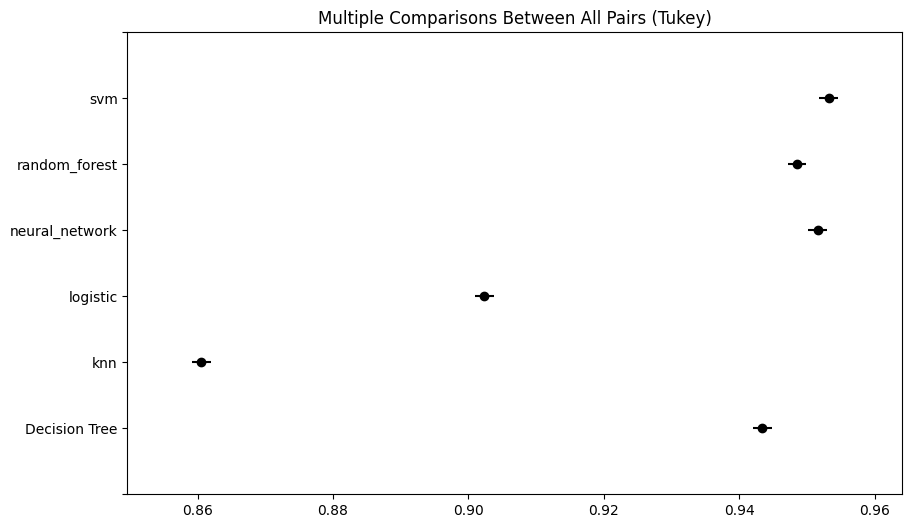

In [73]:
teste_estatistico.plot_simultaneous();

-> The graph with accuracy score of ALL methods

In [74]:
classificador_neural_network = MLPClassifier(activation = 'logistic', batch_size = 10, solver = 'adam', hidden_layer_sizes=(10,10))
classificador_neural_network.fit(X_treino, y_treino)

MLPClassifier(activation='logistic', batch_size=10, hidden_layer_sizes=(10, 10))

In [75]:
classificador_decision_tree = DecisionTreeClassifier(criterion='entropy', min_samples_leaf=1, min_samples_split=2, splitter='best')
classificador_decision_tree.fit(X_treino, y_treino)

DecisionTreeClassifier(criterion='entropy')

In [76]:
classificador_random_forest = RandomForestClassifier(criterion = 'gini', min_samples_leaf = 1, min_samples_split=2, n_estimators = 150)
classificador_random_forest.fit(X_treino, y_treino)
 

RandomForestClassifier(n_estimators=150)

-> because of the normal distribution and accuracy score, I chose neural network, Randomforest and Decision Tree as the best methods for predicting the degree of obsession of people in the data set

In [77]:
import pickle
pickle.dump(classificador_neural_network, open('neural_network_finalizado.sav', 'wb'))
pickle.dump(classificador_random_forest, open('random_forest_finalizado.sav', 'wb'))
pickle.dump(classificador_random_forest, open('decision_tree_finalizado.sav', 'wb'))

-> Saving the methods in the computer

In [78]:
novo_registro = X_scaler[6]
novo_registro = novo_registro.reshape(1, -1)
rede_neural = classificador_neural_network.predict(novo_registro)
arvore = classificador_decision_tree.predict(novo_registro)
random_forest = classificador_random_forest.predict(novo_registro)
print(rede_neural)
print(arvore)
print(random_forest)



['Normal_Weight']
['Normal_Weight']
['Normal_Weight']


In [79]:
df.head(7)

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
5,29.0,Male,1.62,53.0,Sometimes,yes,2.0,3.0,no,no,2.0,no,0.0,0.0,Sometimes,Automobile,Normal_Weight
6,23.0,Female,1.50,55.0,Sometimes,yes,3.0,3.0,no,no,2.0,yes,1.0,0.0,Sometimes,Motorbike,Normal_Weight
7,22.0,Male,1.64,53.0,Sometimes,no,2.0,3.0,no,no,2.0,no,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight


-> A test, I typed the number 6 and I compared with the dataset and the methods is right 

# **6.0 - StoryTelling**

The dataset aims to predict, using the best machine learning methods, how obese people are.
During the dataset, some duplicate rows and outliers were found, they were removed so that machine learning would be cleaner, no column with missing data (NAN) was found.
The dataset, after cleaning, was trained with the variable X with standardization with a space of 20% of the dataset for testing.

After using all the methods, the best hit rate was the SVM, with 96.7%.

But since only one result is important, a search was made for the best parameters for each method (except for naive bayes).
Then we used cross-validation together with k-fold, where we ran the code to be revised 30 times with different random parameters with a 10-fold division by k-fold, as well as testing 6 different algorithms.

30 * 10 * 6 = 1800
The code ran 1800 times for the hit rates of the parameters that were executed.
As a result, the best methods (based on hit rate) were in this order: SVM, Neural network, Random forest, Decision tree, Logistic regression and knn respectively.
However, a normal distribution still needs to be applied to show how much the project was at its best, because if any of the methods used are not normally distributed in machine learning, machine learning could give a very wrong result, thus compromising the entire prediction process.

During this distribution, it was seen that the SVM did not have a normal distribution because its p-value was lower than alpha=0.05, so despite having the best hit rate, without the normal distribution, I preferred not to use the SVM.

With the other results having a normal distribution and a high hit rate, I chose the neural network, random forest and decision tree as the system's main prediction methods.
And with the test done, it was seen that the three methods pointed to 'Normal_Weight' and were right about.
And I've left a code that, if you copy or download the code, you can check whether or not the algorithms will be right for a particular line in the data set. 
Thanks for your attention to this 'notebook' and sorry for any translation errors, I'm not a native American or English speaker.